# Gene Expression Explorer: Colorectal Cancer (GSE50760)
Exploratory analysis of RNA-seq data from 18 colorectal cancer patients (primary tumor, matched normal colon, liver metastasis): PCA, clustering, paired differential expression and pathway enrichment.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import GEOparse

print("Setup complete")

Setup complete


## 1. Data
Downloaded the supplementary files for GSE50760 from GEO. Only FPKM values are available, so DESeq2 cannot be used. Each file is one sample; they are combined into a genes x samples table and labelled with GEO metadata (tumor, normal, metastasis).

In [2]:
import urllib.request, os

os.makedirs("../data", exist_ok=True)
url = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE50nnn/GSE50760/suppl/GSE50760_RAW.tar"
urllib.request.urlretrieve(url, "../data/GSE50760_RAW.tar")

print(os.path.getsize("../data/GSE50760_RAW.tar") / 1e6, "MB")

7.74144 MB


In [3]:
import tarfile, os

tar_path = "../data/GSE50760_RAW.tar"
out_dir = "../data/raw_files"
os.makedirs(out_dir, exist_ok=True)

with tarfile.open(tar_path) as tar:
    tar.extractall(out_dir)

files = sorted(os.listdir(out_dir))
print(len(files), "files")
print(files[:5])

54 files
['GSM1228184_AMC_2.1_FPKM.txt.gz', 'GSM1228185_AMC_3.1_FPKM.txt.gz', 'GSM1228186_AMC_5.1_FPKM.txt.gz', 'GSM1228187_AMC_6.1_FPKM.txt.gz', 'GSM1228188_AMC_7.1_FPKM.txt.gz']


In [4]:
import os
print(os.getcwd())
print(os.listdir("../data"))

C:\Users\Shameer\Documents\gene-expression-explorer\notebooks
['de_tumor_vs_normal.csv', 'enrichment_down.csv', 'enrichment_up.csv', 'GSE50760_family.soft.gz', 'GSE50760_RAW.tar', 'raw_files']


In [5]:
import os

out_dir = "../data/raw_files"
files = sorted(os.listdir(out_dir))
print(len(files), "files")
for f in files[:5]:
    print(f)

54 files
GSM1228184_AMC_2.1_FPKM.txt.gz
GSM1228185_AMC_3.1_FPKM.txt.gz
GSM1228186_AMC_5.1_FPKM.txt.gz
GSM1228187_AMC_6.1_FPKM.txt.gz
GSM1228188_AMC_7.1_FPKM.txt.gz


In [6]:
import pandas as pd, os

out_dir = "../data/raw_files"
files = sorted(os.listdir(out_dir))

df = pd.read_csv(os.path.join(out_dir, files[0]), sep="\t")
print(df.shape)
df.head(10)

(23505, 2)


,genes,AMC_2.1_FPKM
0,A1BG,0.241109
1,A1BG-AS1,0.028173
2,A1CF,16.257000
3,A2LD1,1.566140
4,A2M,33.146900
5,A2ML1,0.000000
6,A2MP1,0.000000
7,A4GALT,0.707430
8,A4GNT,0.000000
9,AA06,0.000000


In [7]:
import pandas as pd, os

out_dir = "../data/raw_files"
files = sorted(os.listdir(out_dir))

series = {}
for f in files:
    gsm = f.split("_")[0]                      # e.g. GSM1228184
    d = pd.read_csv(os.path.join(out_dir, f), sep="\t", index_col=0)
    s = d.iloc[:, 0]
    s = s[~s.index.duplicated(keep="first")]   # drop duplicate gene names if any
    series[gsm] = s

fpkm = pd.DataFrame(series)
print(fpkm.shape)        # expect about (23505, 54)
print(fpkm.isna().sum().sum(), "missing values")
fpkm.iloc[:5, :5]

(23503, 54)
0 missing values


,GSM1228184,GSM1228185,GSM1228186,GSM1228187,GSM1228188
genes,,,,,
A1BG,0.241109,0.413634,0.773777,0.290182,0.508287
A1BG-AS1,0.028173,0.021606,0.149216,0.054038,0.083540
A1CF,16.257000,12.422300,4.637920,4.212960,5.013990
A2LD1,1.566140,4.625220,3.556490,6.135820,6.769770
A2M,33.146900,46.837500,114.636000,37.306200,22.565800


In [8]:
import GEOparse

gse = GEOparse.get_GEO("GSE50760", destdir="../data/")
meta = gse.phenotype_data
print(meta.shape)
print(meta.columns.tolist())
meta[["title", "source_name_ch1"]].head(15)

22-Oct-2026 13:32:28 DEBUG utils - Directory ../data/ already exists. Skipping.
22-Oct-2026 13:32:28 INFO GEOparse - File already exist: using local version.
22-Oct-2026 13:32:28 INFO GEOparse - Parsing ../data/GSE50760_family.soft.gz: 
22-Oct-2026 13:32:28 DEBUG GEOparse - DATABASE: GeoMiame
22-Oct-2026 13:32:28 DEBUG GEOparse - SERIES: GSE50760
22-Oct-2026 13:32:28 DEBUG GEOparse - PLATFORM: GPL11154
22-Oct-2026 13:32:28 DEBUG GEOparse - SAMPLE: GSM1228184
22-Oct-2026 13:32:28 DEBUG GEOparse - SAMPLE: GSM1228185
22-Oct-2026 13:32:28 DEBUG GEOparse - SAMPLE: GSM1228186
22-Oct-2026 13:32:28 DEBUG GEOparse - SAMPLE: GSM1228187
22-Oct-2026 13:32:28 DEBUG GEOparse - SAMPLE: GSM1228188
22-Oct-2026 13:32:28 DEBUG GEOparse - SAMPLE: GSM1228189
22-Oct-2026 13:32:29 DEBUG GEOparse - SAMPLE: GSM1228190
22-Oct-2026 13:32:29 DEBUG GEOparse - SAMPLE: GSM1228191
22-Oct-2026 13:32:29 DEBUG GEOparse - SAMPLE: GSM1228192
22-Oct-2026 13:32:29 DEBUG GEOparse - SAMPLE: GSM1228193
22-Oct-2026 13:32:29 DEB

(54, 33)
['title', 'geo_accession', 'status', 'submission_date', 'last_update_date', 'type', 'channel_count', 'source_name_ch1', 'organism_ch1', 'taxid_ch1', 'characteristics_ch1.0.tissue', 'characteristics_ch1.1.ajcc stage', 'molecule_ch1', 'extract_protocol_ch1', 'data_processing', 'platform_id', 'contact_name', 'contact_email', 'contact_phone', 'contact_department', 'contact_institute', 'contact_address', 'contact_city', 'contact_zip/postal_code', 'contact_country', 'instrument_model', 'library_selection', 'library_source', 'library_strategy', 'relation', 'supplementary_file_1', 'series_id', 'data_row_count']


,title,source_name_ch1
GSM1228184,primary colorectal cancer AMC_2-1,primary colorectal cancer
GSM1228185,primary colorectal cancer AMC_3-1,primary colorectal cancer
GSM1228186,primary colorectal cancer AMC_5-1,primary colorectal cancer
GSM1228187,primary colorectal cancer AMC_6-1,primary colorectal cancer
GSM1228188,primary colorectal cancer AMC_7-1,primary colorectal cancer
GSM1228189,primary colorectal cancer AMC_8-1,primary colorectal cancer
GSM1228190,primary colorectal cancer AMC_9-1,primary colorectal cancer
GSM1228191,primary colorectal cancer AMC_10-1,primary colorectal cancer
GSM1228192,primary colorectal cancer AMC_12-1,primary colorectal cancer
GSM1228193,primary colorectal cancer AMC_13-1,primary colorectal cancer


In [9]:
meta["source_name_ch1"].value_counts()

source_name_ch1
primary colorectal cancer    18
normal colon                 18
metastasized cancer          18
Name: count, dtype: int64

In [10]:
import re

clean = meta[["title", "source_name_ch1"]].copy()
clean["condition"] = clean["source_name_ch1"].str.lower().map(
    lambda s: "tumor" if "primary" in s else ("normal" if "normal" in s else "metastasis")
)
clean["patient"] = clean["title"].str.extract(r"(AMC_\d+)")[0]

print(clean["condition"].value_counts())
print(clean["patient"].nunique(), "patients")
clean.head()

condition
tumor         18
normal        18
metastasis    18
Name: count, dtype: int64
18 patients


,title,source_name_ch1,condition,patient
GSM1228184,primary colorectal cancer AMC_2-1,primary colorectal cancer,tumor,AMC_2
GSM1228185,primary colorectal cancer AMC_3-1,primary colorectal cancer,tumor,AMC_3
GSM1228186,primary colorectal cancer AMC_5-1,primary colorectal cancer,tumor,AMC_5
GSM1228187,primary colorectal cancer AMC_6-1,primary colorectal cancer,tumor,AMC_6
GSM1228188,primary colorectal cancer AMC_7-1,primary colorectal cancer,tumor,AMC_7


In [11]:
print(set(fpkm.columns) == set(clean.index))   # should be True
fpkm = fpkm[clean.index]                       # same order as the metadata

True


## 2. Filtering and normalization
Kept genes with FPKM >= 1 in at least 10 samples (23,503 to 14,217 genes), then applied log2(FPKM + 1).

In [12]:
import numpy as np

# keep genes with FPKM >= 1 in at least 10 samples
keep = (fpkm >= 1).sum(axis=1) >= 10
fpkm_f = fpkm[keep]
print(f"{fpkm.shape[0]} -> {fpkm_f.shape[0]} genes")

log_fpkm = np.log2(fpkm_f + 1)

23503 -> 14217 genes


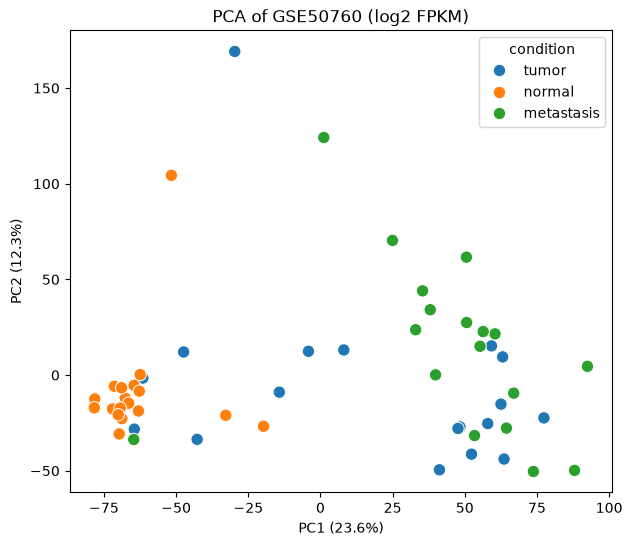

In [13]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("../figures", exist_ok=True)

X = StandardScaler().fit_transform(log_fpkm.T)      # samples x genes
pca = PCA(n_components=5)
pcs = pca.fit_transform(X)

pca_df = pd.DataFrame(pcs[:, :2], columns=["PC1", "PC2"], index=log_fpkm.columns)
pca_df["condition"] = clean["condition"]

plt.figure(figsize=(7, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="condition", s=80)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("PCA of GSE50760 (log2 FPKM)")
plt.savefig("../figures/pca.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. PCA
PCA on standardized log2 expression. Normal samples cluster tightly, tumors are more spread out, and metastases (liver tissue) separate from colon samples. A few outlier samples are kept and noted rather than removed.

In [14]:
pca_df["PC1_abs"] = pca_df["PC1"].abs()
pca_df.sort_values("PC2", ascending=False).head(5)

,PC1,PC2,condition,PC1_abs
GSM1228190,-29.674138,169.110908,tumor,29.674138
GSM1228227,1.159701,124.158122,metastasis,1.159701
GSM1228212,-51.624273,104.405600,normal,51.624273
GSM1228224,24.951431,70.376677,metastasis,24.951431
GSM1228236,50.566979,61.626152,metastasis,50.566979


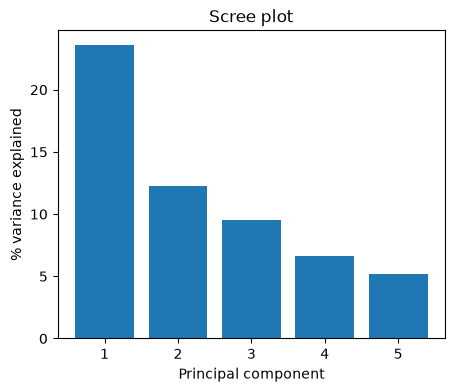

In [15]:
plt.figure(figsize=(5, 4))
plt.bar(range(1, 6), pca.explained_variance_ratio_ * 100)
plt.xlabel("Principal component")
plt.ylabel("% variance explained")
plt.title("Scree plot")
plt.savefig("../figures/scree.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Clustering
Hierarchical clustering (Ward) of the 500 most variable genes, plus k-means on the top 5 PCs. k = 3 has the best silhouette (0.43), but agreement with true labels is moderate (ARI = 0.38), because tumors are heterogeneous.

C:\Users\Shameer\miniconda3\envs\geo-explorer\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
C:\Users\Shameer\miniconda3\envs\geo-explorer\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


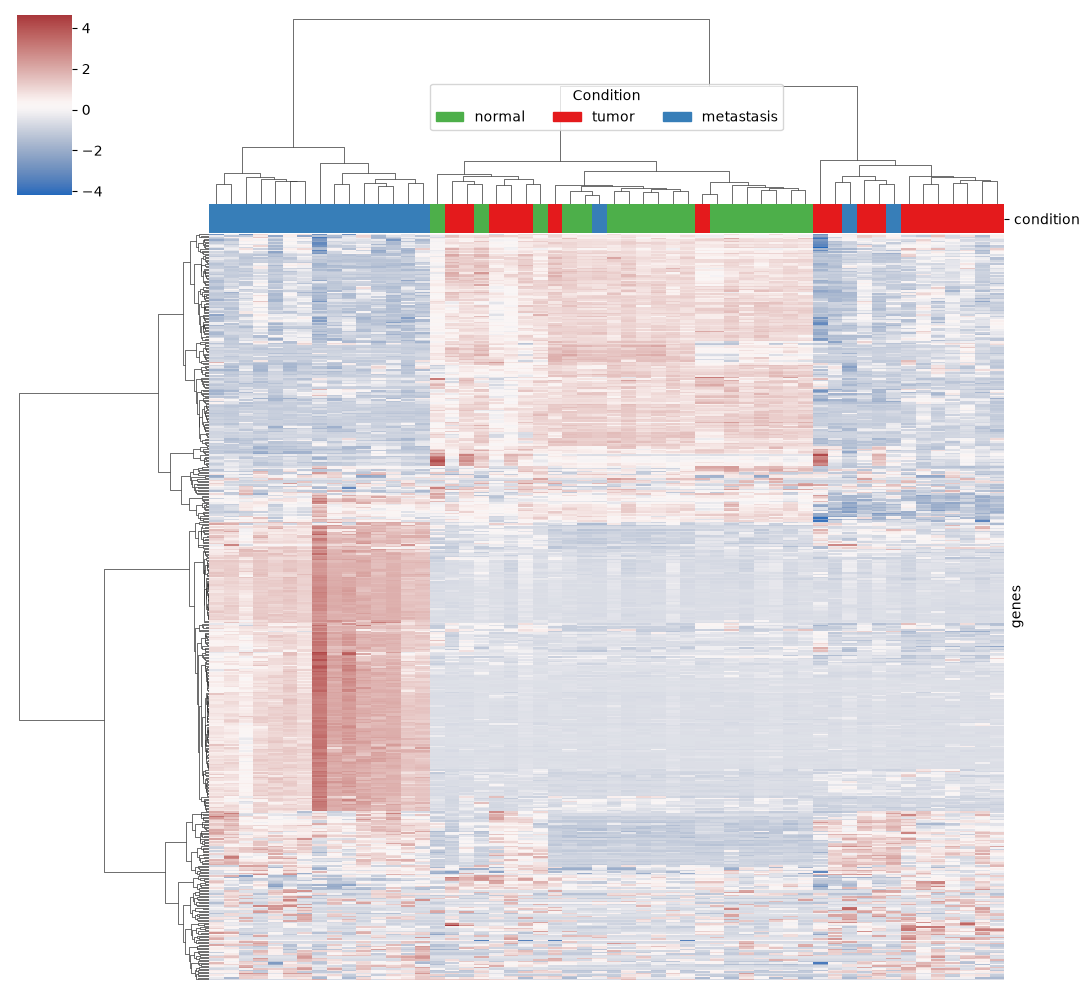

In [16]:
top_genes = log_fpkm.var(axis=1).sort_values(ascending=False).head(500).index
subset = log_fpkm.loc[top_genes]

palette = {"normal": "#4daf4a", "tumor": "#e41a1c", "metastasis": "#377eb8"}
col_colors = clean["condition"].map(palette)

g = sns.clustermap(
    subset,
    z_score=0,                 # scale each gene across samples
    cmap="vlag",
    col_colors=col_colors,
    method="ward",
    metric="euclidean",
    figsize=(11, 10),
    yticklabels=False,
    xticklabels=False,
)

# legend for the colour bar
from matplotlib.patches import Patch
handles = [Patch(color=c, label=l) for l, c in palette.items()]
g.ax_col_dendrogram.legend(handles=handles, loc="center", ncol=3, title="Condition")

g.savefig("../figures/heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

In [17]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

pcs5 = pcs[:, :5]
for k in [2, 3, 4]:
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(pcs5)
    print(k, "clusters, silhouette =", round(silhouette_score(pcs5, labels), 3))

# how well do 3 clusters match the real conditions?
km3 = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(pcs5)
print("Agreement with true labels (ARI):", round(adjusted_rand_score(clean["condition"], km3), 3))

2 clusters, silhouette = 0.392
3 clusters, silhouette = 0.428
4 clusters, silhouette = 0.421
Agreement with true labels (ARI): 0.38


## 5. Differential expression (tumor vs. matched normal)
Paired t-test on log2(FPKM + 1) across 18 patients with Benjamini-Hochberg correction. Significant = FDR < 0.05 and |log2FC| > 1. Result: 328 genes up, 528 down. Known colon markers behave as expected (CA1, CA2, GUCA2A, GUCA2B down; MMP1, MMP7 up).

In [18]:
from scipy import stats
from statsmodels.stats.multitest import multipletests

# map each patient to their tumor and normal sample IDs
t_map = clean[clean.condition == "tumor"].assign(gsm=lambda d: d.index).set_index("patient")["gsm"]
n_map = clean[clean.condition == "normal"].assign(gsm=lambda d: d.index).set_index("patient")["gsm"]
patients = sorted(set(t_map.index) & set(n_map.index))
print(len(patients), "patients with both tumor and normal")

tum = log_fpkm[t_map[patients].values].values   # genes x patients
nor = log_fpkm[n_map[patients].values].values   # same patient order

t_stat, pvals = stats.ttest_rel(tum, nor, axis=1)
log2fc = (tum - nor).mean(axis=1)               # mean paired difference in log2 units

res = pd.DataFrame({"log2FoldChange": log2fc, "pvalue": pvals}, index=log_fpkm.index).dropna()
res["padj"] = multipletests(res["pvalue"], method="fdr_bh")[1]

res["status"] = "NS"
res.loc[(res.padj < 0.05) & (res.log2FoldChange > 1), "status"] = "Up"
res.loc[(res.padj < 0.05) & (res.log2FoldChange < -1), "status"] = "Down"

print(res["status"].value_counts())
res.sort_values("padj").head(10)

18 patients with both tumor and normal
status
NS      13361
Down      528
Up        328
Name: count, dtype: int64


,log2FoldChange,pvalue,padj,status
genes,,,,
OTOP2,-4.215627,3.747159e-10,0.000005,Down
BEST4,-4.533734,7.864112e-10,0.000006,Down
UNC5C,-0.789179,2.227361e-09,0.000011,NS
SPIB,-3.267103,5.649982e-09,0.000016,Down
CA7,-4.651988,4.829418e-09,0.000016,Down
OTOP3,-0.986233,1.348302e-08,0.000032,NS
RSPO2,-1.167131,1.623032e-08,0.000033,Down
ZNF575,-1.180408,7.635748e-08,0.000120,Down
GLP2R,-1.027702,8.454239e-08,0.000120,Down


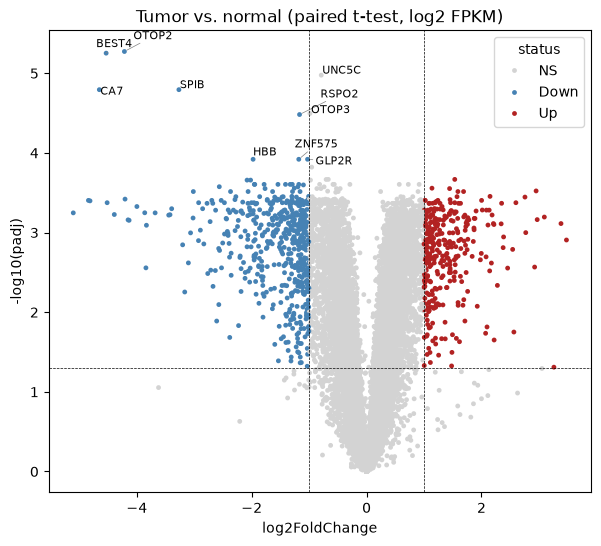

In [19]:
res["-log10(padj)"] = -np.log10(res["padj"].clip(lower=1e-300))

plt.figure(figsize=(7, 6))
sns.scatterplot(data=res, x="log2FoldChange", y="-log10(padj)", hue="status",
                palette={"NS": "lightgrey", "Up": "firebrick", "Down": "steelblue"},
                s=12, linewidth=0)
plt.axvline(-1, ls="--", c="k", lw=0.5)
plt.axvline(1, ls="--", c="k", lw=0.5)
plt.axhline(-np.log10(0.05), ls="--", c="k", lw=0.5)

from adjustText import adjust_text
texts = [plt.text(r.log2FoldChange, r["-log10(padj)"], g, fontsize=8)
         for g, r in res.sort_values("padj").head(10).iterrows()]
adjust_text(texts, arrowprops=dict(arrowstyle="-", color="grey", lw=0.5))

plt.title("Tumor vs. normal (paired t-test, log2 FPKM)")
plt.savefig("../figures/volcano.png", dpi=300, bbox_inches="tight")
plt.show()

res.to_csv("../data/de_tumor_vs_normal.csv")

## 6. Pathway enrichment
Enrichr (GO Biological Process 2023, KEGG 2021) on the up and down gene lists, using the 14,217 tested genes as background. Many GO terms share the same genes, so they are not independent findings.

In [20]:
import gseapy as gp

up_genes = res[res.status == "Up"].index.tolist()
down_genes = res[res.status == "Down"].index.tolist()
print(len(up_genes), "up,", len(down_genes), "down")

background = log_fpkm.index.tolist()   # use the genes you actually tested

enr_up = gp.enrichr(gene_list=up_genes, gene_sets=["GO_Biological_Process_2023", "KEGG_2021_Human"],
                    organism="human", background=background, outdir=None)
enr_down = gp.enrichr(gene_list=down_genes, gene_sets=["GO_Biological_Process_2023", "KEGG_2021_Human"],
                      organism="human", background=background, outdir=None)



328 up, 528 down


In [21]:
cols = ["Gene_set", "Term", "Adjusted P-value", "Odds Ratio", "Genes"]

print("UP in tumor")
display(enr_up.results.sort_values("Adjusted P-value")[cols].head(10))

print("DOWN in tumor")
display(enr_down.results.sort_values("Adjusted P-value")[cols].head(10))

UP in tumor


,Gene_set,Term,Adjusted P-value,Odds Ratio,Genes
0,GO_Biological_Process_2023,External Encapsulating Structure Organization ...,3.000563e-16,20.306789,COL15A1;MMP7;MMP1;COL11A1;MMP3;ADAMTS12;MMP9;C...
1,GO_Biological_Process_2023,Extracellular Structure Organization (GO:0043062),3.000563e-16,19.899216,COL15A1;MMP7;MMP1;COL11A1;MMP3;ADAMTS12;MMP9;C...
2,GO_Biological_Process_2023,Extracellular Matrix Organization (GO:0030198),1.816971e-15,12.500662,COL18A1;COL15A1;COL11A1;COL12A1;ADAMTS12;LOXL2...
3,GO_Biological_Process_2023,Regulation Of Cell Population Proliferation (G...,2.163613e-10,4.031688,COL18A1;REG3A;IFITM1;UHRF1;REG1B;HILPDA;REG1A;...
1979,KEGG_2021_Human,IL-17 signaling pathway,1.057033e-08,11.428060,CEBPB;HSP90AB1;MMP1;MMP3;CXCL1;CXCL3;CXCL2;MMP...
1980,KEGG_2021_Human,Protein digestion and absorption,1.057033e-08,12.856555,COL18A1;COL15A1;COL11A1;COL12A1;COL1A1;COL3A1;...
4,GO_Biological_Process_2023,Collagen Fibril Organization (GO:0030199),2.763739e-08,22.915427,COL1A1;COL18A1;ADAMTS2;COL3A1;COL1A2;COL5A1;CO...
5,GO_Biological_Process_2023,Antimicrobial Humoral Immune Response Mediated...,4.900581e-08,20.919764,REG3A;CXCL10;CXCL11;DEFA6;REG1B;REG1A;CXCL1;CX...
1981,KEGG_2021_Human,ECM-receptor interaction,1.023997e-06,10.510633,COMP;COL1A1;COL1A2;COL4A2;COL4A1;ITGA2;TNC;SPP...
7,GO_Biological_Process_2023,Antimicrobial Humoral Response (GO:0019730),2.175281e-06,12.991048,REG3A;CXCL10;CXCL11;DEFA6;REG1B;REG1A;CXCL1;CX...


DOWN in tumor


,Gene_set,Term,Adjusted P-value,Odds Ratio,Genes
0,GO_Biological_Process_2023,Cellular Response To Zinc Ion (GO:0071294),0.000008,42.104615,MT2A;P2RX4;MT1M;MT1F;MT1G;MT1X;MT1H;MT1E
2221,KEGG_2021_Human,Neuroactive ligand-receptor interaction,0.000016,5.124129,PTGER4;VIPR1;EDN2;THRB;EDN3;GLP2R;GCG;SSTR1;AD...
2222,KEGG_2021_Human,Mineral absorption,0.000040,9.080452,SLC9A3;MT2A;SLC6A19;MT1M;MT1F;MT1G;MT1X;MT1H;T...
2223,KEGG_2021_Human,Bile secretion,0.000050,6.619903,UGT1A10;ABCB1;AQP8;NR1H4;CYP3A4;SLC4A4;ADCY5;S...
2224,KEGG_2021_Human,Drug metabolism,0.000072,5.237381,CDA;UGT1A10;GSTM2;ADH1C;MAOA;ADH1B;CYP3A4;FMO5...
1,GO_Biological_Process_2023,Response To Zinc Ion (GO:0010043),0.000201,19.130070,MT2A;P2RX4;MT1M;MT1F;MT1G;MT1X;MT1H;MT1E
2,GO_Biological_Process_2023,Cellular Response To Copper Ion (GO:0071280),0.000592,20.422265,MT2A;MT1M;MT1F;MT1G;MT1X;MT1H;MT1E
3,GO_Biological_Process_2023,Response To Copper Ion (GO:0046688),0.001158,16.706683,MT2A;MT1M;MT1F;MT1G;MT1X;MT1H;MT1E
2225,KEGG_2021_Human,Nitrogen metabolism,0.001303,21.802103,CA12;CA1;CA2;CA4;CA7
2226,KEGG_2021_Human,Cytokine-cytokine receptor interaction,0.001324,3.196750,ACVRL1;CCL14;CNTFR;CCL23;TNFRSF13B;IL1R2;CXCL1...


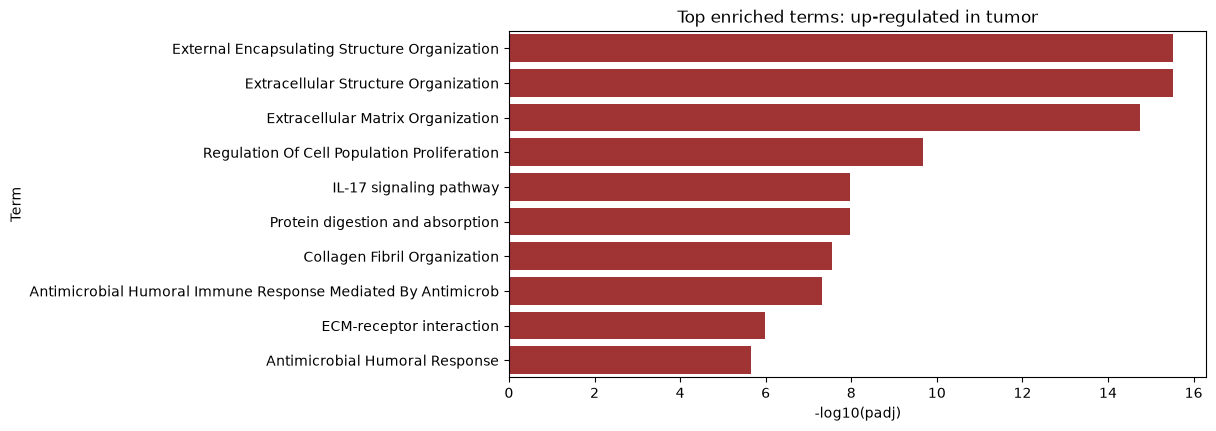

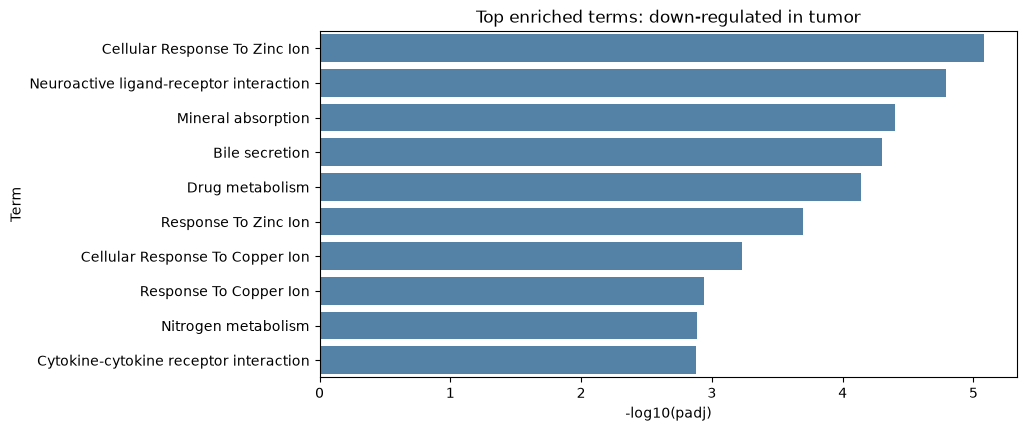

In [22]:
for name, enr in [("up", enr_up), ("down", enr_down)]:
    d = enr.results.sort_values("Adjusted P-value").head(10).copy()
    d["-log10(padj)"] = -np.log10(d["Adjusted P-value"])
    d["Term"] = d["Term"].str.replace(r"\s*\(GO:\d+\)", "", regex=True).str.slice(0, 60)
    plt.figure(figsize=(9, 4.5))
    sns.barplot(data=d, y="Term", x="-log10(padj)",
                color="steelblue" if name == "down" else "firebrick")
    plt.title(f"Top enriched terms: {name}-regulated in tumor")
    plt.savefig(f"../figures/enrichment_{name}.png", dpi=300, bbox_inches="tight")
    plt.show()

In [23]:
enr_up.results.to_csv("../data/enrichment_up.csv", index=False)
enr_down.results.to_csv("../data/enrichment_down.csv", index=False)

## Conclusions
1. Normal colon samples cluster tightly; tumors are heterogeneous; metastases separate from colon tissue.
2. 328 genes are up and 528 down in tumor vs. matched normal.
3. Up-regulated genes are enriched for extracellular matrix remodeling, collagen organization and proliferation, consistent with tumor invasion.
4. Down-regulated genes are enriched for normal colon functions (mineral absorption, bile secretion, drug metabolism).
5. Limitations: FPKM only (no DESeq2), 18 pairs, no validation dataset.